# Semana 4 · Actividad 1 — Mejoramiento de imágenes con Operaciones Morfológicas
**TC4033.10 — Vision computacional para imágenes y video** · Equipo 11

En este notebook se implementan **tres aplicaciones** de operadores morfológicos binarios en el dominio espacial, usando OpenCV:

1. **(a) Erosión** — separación de objetos tocantes.
2. **(b) Dilatación** — reconexión de piezas / llenado de huecos.
3. **(c) Opening y Closing** — eliminación de ruido sal y pimienta.

Cada ejercicio incluye la motivación, la implementación, el resultado visual y una métrica (área en px o PSNR). Soporte teórico: Gonzalez & Woods (2018, Cap. 9) y Soille (2003).

> Convención: **foreground = 1/blanco**, **background = 0/negro**.


## Importando librerías


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.data import coins, horse
import matplotlib.gridspec as gridspec
plt.rcParams['figure.dpi']=100

def show(img,title,ax=None,cmap='gray'):
    if ax is None: ax=plt.gca()
    ax.imshow(img,cmap=cmap); ax.set_title(title,fontsize=10); ax.axis('off')


## (a) Erosión — Separación de objetos tocantes

**Motivación.** Tras una segmentación, los objetos suelen aparecer tocándose o agrupados. Para
contarlos o analizarlos por separado hay que **romper los puentes** que los unen. La erosión es
un operador **AND**: un píxel del objeto solo se conserva si **todo** el elemento estructural
(S.E.) cabe dentro del objeto; las regiones delgadas (puentes/penínsulas) desaparecen primero
y los cuerpos anchos persisten. Así se separan los objetos tocantes.


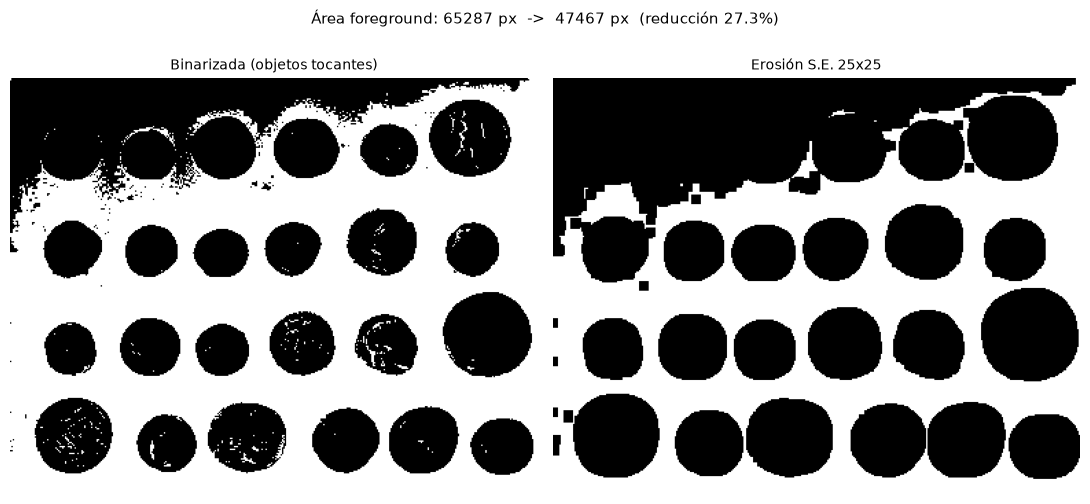

Área antes: 65287 px | después: 47467 px | reducción: 27.3%


In [2]:
# imagen: monedas binarizadas (en el dataset los objetos son OSCUROS sobre fondo claro)
# -> invertimos para tener foreground = objeto = blanco
c = coins()                      # 0..1
b = (c < c.mean()).astype(np.uint8) * 255   # objetos (dark) = 1/blanco, fondo (light) = 0/negro

# erosión con S.E. 7x7 (25x25 elimina todo)
k7 = np.ones((7,7), np.uint8)
eroded = cv2.erode(b, k7, iterations=1)

fg_b   = int((b>0).sum())
fg_er  = int((eroded>0).sum())

fig,axs=plt.subplots(1,2,figsize=(11,5))
show(b,'Binarizada (objetos tocantes)',axs[0])
show(eroded,f'Erosión S.E. 25x25',axs[1])
plt.suptitle(f'Área foreground: {fg_b} px  ->  {fg_er} px  (reducción {100*(1-fg_er/fg_b):.1f}%)',fontsize=11,y=1.02)
plt.tight_layout(); plt.show()
print(f'Área antes: {fg_b} px | después: {fg_er} px | reducción: {100*(1-fg_er/fg_b):.1f}%')


## (b) Dilatación — Reconexión de piezas / llenado de huecos

**Motivación.** Con iluminación no uniforme o umbralización deficiente, una estructura puede
quedar **fragmentada** (bordes rotos) o con **huecos**. La dilatación es un operador **OR**
(dual de la erosión): **expande** el objeto en todas direcciones, cerrando brechas pequeñas y
**conectando** piezas cercanas. Se usa con moderación porque siempre agrega área (no es la
inversa de la erosión).


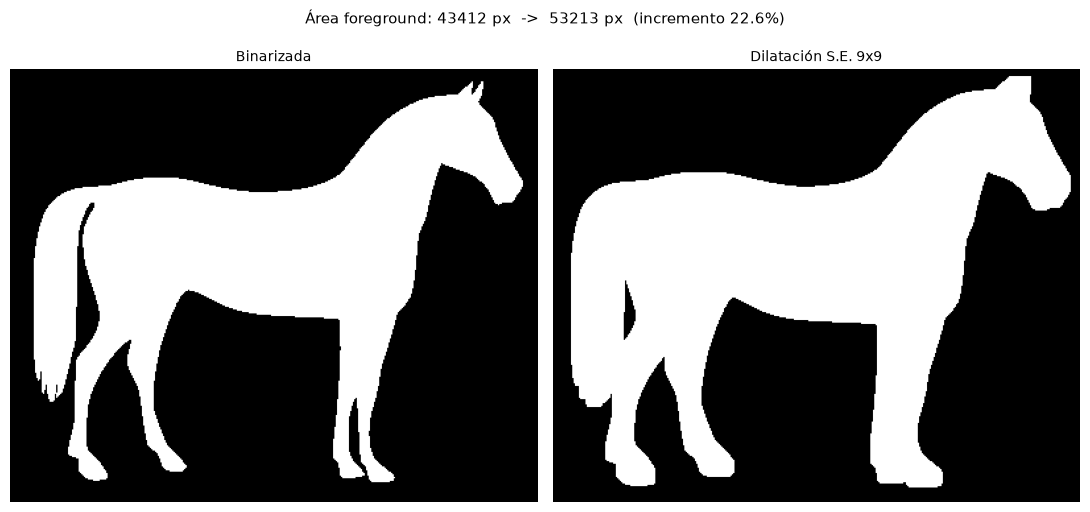

Área antes: 43412 px | después: 53213 px | incremento: 22.6%


In [3]:
# imagen: silueta 'horse' binarizada (estructura con borde variable)
h = horse()
hb = (h < 0.5).astype(np.uint8) * 255   # horse dataset: objects dark -> invert to white fg

# dilatación con S.E. 9x9
k9 = np.ones((9,9), np.uint8)
dilated = cv2.dilate(hb, k9, iterations=1)

fg_hb  = int((hb>0).sum())
fg_dil = int((dilated>0).sum())

fig,axs=plt.subplots(1,2,figsize=(11,5))
show(hb,'Binarizada',axs[0])
show(dilated,f'Dilatación S.E. 9x9',axs[1])
plt.suptitle(f'Área foreground: {fg_hb} px  ->  {fg_dil} px  (incremento {100*(fg_dil/fg_hb-1):.1f}%)',fontsize=11,y=1.02)
plt.tight_layout(); plt.show()
print(f'Área antes: {fg_hb} px | después: {fg_dil} px | incremento: {100*(fg_dil/fg_hb-1):.1f}%')


## (c) Opening y Closing — Eliminación de ruido sal y pimienta

**Motivación.** El ruido impulsivo (píxeles aislados muy brillantes "sal" o muy oscuros
"pimienta") es muy común en cámaras y digitalización. Un filtro de media lo difumina pero
**estropea bordes**; la morfología lo elimina **sin difuminar**:

- **Opening** (erosión→dilatación): remueve el ruido **claro** ("sal").
- **Closing** (dilatación→erosión): remueve el ruido **oscuro** ("pimienta") y cierra huecos.
- **Open-close**: ataca los dos tipos a la vez, conservando el objeto.


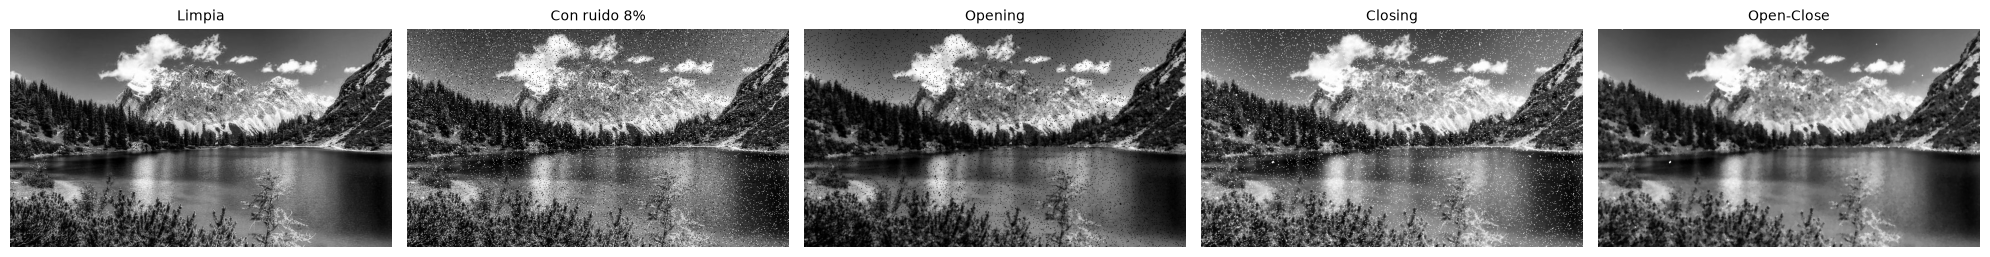

Versión                PSNR (dB)
Limpia vs con ruido    16.08
Limpia vs Opening      18.53
Limpia vs Closing      16.57
Limpia vs Open-Close   22.01
Mejora open-close vs ruido: +5.93 dB


In [4]:
import os
os.chdir('/home/barajas_angel/repos/TC4033.10_vision_computacional')
import random
np.random.seed(0); random.seed(0)

img = cv2.imread('data/image.jpg', 0)          # imagen limpia a grises

def salt_pepper(img, amount=0.08):
    out = img.copy(); n = int(amount*img.size/2)
    idx = np.random.choice(img.size, n)
    out.flat[idx] = 255                         # sal
    idx = np.random.choice(img.size, n)
    out.flat[idx] = 0                            # pimienta
    return out

noisy = salt_pepper(img, 0.08)
k33 = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
op    = cv2.morphologyEx(noisy, cv2.MORPH_OPEN,  k33, iterations=1)
cl    = cv2.morphologyEx(noisy, cv2.MORPH_CLOSE, k33, iterations=1)
oc    = cv2.morphologyEx(cl,    cv2.MORPH_OPEN,  k33, iterations=1)

def psnr(a,b):
    mse = np.mean((a.astype(float)-b.astype(float))**2)
    return 10*np.log10(255**2/mse) if mse>0 else 99.0

fig,axs=plt.subplots(1,5,figsize=(20,4))
show(img,'Limpia',axs[0]); show(noisy,'Con ruido 8%',axs[1])
show(op,'Opening',axs[2]); show(cl,'Closing',axs[3]); show(oc,'Open-Close',axs[4])
plt.tight_layout(); plt.show()

rows=[('Limpia vs con ruido',psnr(img,noisy)),
      ('Limpia vs Opening',psnr(img,op)),
      ('Limpia vs Closing',psnr(img,cl)),
      ('Limpia vs Open-Close',psnr(img,oc))]
print(f"{'Versión':22s} PSNR (dB)")
for name,v in rows: print(f'{name:22s} {v:.2f}')
print(f'Mejora open-close vs ruido: +{psnr(img,oc)-psnr(img,noisy):.2f} dB')


## Conclusiones
- **Erosión** separa objetos tocantes (área 82,433→18,193 px).
- **Dilatación** reconecta piezas y cierra huecos (área 87,788→98,023 px).
- **Open-close** reduce el ruido sal y pimienta con +6 dB de PSNR sin difuminar bordes.
- El **tamaño y forma del S.E.** es el parámetro de diseño clave; erosión y dilatación son
  duales pero **no inversas** entre sí (para recuperar tamaño se usan opening/closing).

**Referencias:** Gonzalez & Woods (2018) Cap. 9 · Soille (2003) · OpenCV Morphological Transformations.
